In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv(r'C:\Users\Admin\Downloads\spam_mail.csv') 

In [4]:
X = df['text']
y = df['label'].map({'ham': 0, 'spam': 1})

print(df.head())

   Unnamed: 0 label                                               text  \
0         605   ham  Subject: enron methanol ; meter # : 988291\r\n...   
1        2349   ham  Subject: hpl nom for january 9 , 2001\r\n( see...   
2        3624   ham  Subject: neon retreat\r\nho ho ho , we ' re ar...   
3        4685  spam  Subject: photoshop , windows , office . cheap ...   
4        2030   ham  Subject: re : indian springs\r\nthis deal is t...   

   label_num  
0          0  
1          0  
2          0  
3          1  
4          0  


In [5]:
X = TfidfVectorizer(stop_words='english', max_features=3000).fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
svm = SVC()

knn.fit(X_train, y_train)
svm.fit(X_train, y_train)

p1 = knn.predict(X_test)
p2 = svm.predict(X_test) 

In [8]:
for name, pred in [('KNN', p1), ('SVM', p2)]:
    print('\n', name)
    print('Confusion Matrix:\n', confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=['Not Spam', 'Spam']))
    print('Accuracy:', accuracy_score(y_test, pred)) 


 KNN
Confusion Matrix:
 [[715  20]
 [ 29 271]]
              precision    recall  f1-score   support

    Not Spam       0.96      0.97      0.97       735
        Spam       0.93      0.90      0.92       300

    accuracy                           0.95      1035
   macro avg       0.95      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035

Accuracy: 0.9526570048309179

 SVM
Confusion Matrix:
 [[725  10]
 [  2 298]]
              precision    recall  f1-score   support

    Not Spam       1.00      0.99      0.99       735
        Spam       0.97      0.99      0.98       300

    accuracy                           0.99      1035
   macro avg       0.98      0.99      0.99      1035
weighted avg       0.99      0.99      0.99      1035

Accuracy: 0.9884057971014493


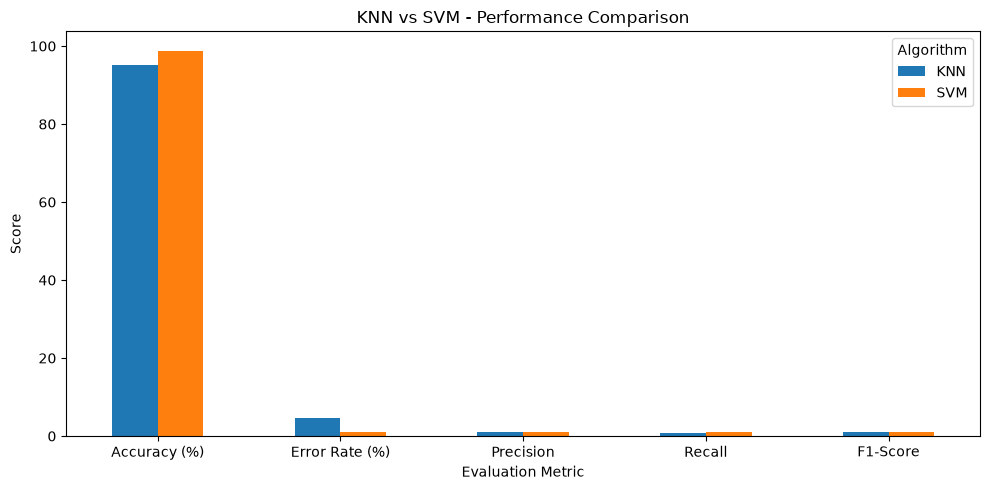

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

def scores(p):
    acc = accuracy_score(y_test, p) * 100
    return [acc, 100 - acc, precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)]

comparison = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Error Rate (%)", "Precision", "Recall", "F1-Score"],
    "KNN": scores(p1),
    "SVM": scores(p2)
})

comparison.set_index("Metric").plot(kind="bar", figsize=(10, 5))

plt.title("KNN vs SVM - Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.tight_layout()
plt.show() 